### Import Libraries

In [ ]:
# for manipulations
import numpy as np
import pandas as pd

In [ ]:
# for data visualizations
import matplotlib.pyplot as plt
import seaborn as sns
plt.rcParams['axes.autolimit_mode'] = 'round_numbers'
plt.style.use('fivethirtyeight')

In [ ]:
# for Checking Random Walk
from statsmodels.tsa.stattools import adfuller

In [ ]:
# For Prediction
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf, plot_predict

In [ ]:
# lets import the warnings library so that we can avoid warnings
import warnings
warnings.filterwarnings('ignore')

In [ ]:
# For Normalization
from sklearn.preprocessing import MinMaxScaler

In [ ]:
# Custom module
from TimeSeriesCustFunc import *

__SARIMAX_Graph__(`data`, `col`, `pred`, `time_range`, `title`, `xlabel, ylabel`, `legend=['Observed', 'Predicted']`)
* __SARIMAX_Graph__(`data`, `col_to_pred`, `[pred, pred_ci]`, `[time_range_for_Observation, time_range_for_Prediction]`, `title_of_plot`, `xlabel`, `ylabel`, `[legend_for_Observation, legend_for_Prediction]`)

__Run_SARIMAX__(`data`, `mod_order`, `time_range`, `col`, `season_order=(0,0,0,0)`, `title=''`, `xlabel=''`, `ylabel=''`)
* __Run_SARIMAX__(`data`, `(p, d, q)`, `[time_range_for_Observation, time_range_for_Prediction]`, `col_to_pred`, `(P, D, Q, m)`, `title_of_plot`, `xlabel`, `ylabel`)
* return model

__AIC_BIC_withOrderRange__(`data`, `p=1`, `d=1`, `q=1`, `P=1`, `D=1`, `Q=1`, `m=1`)
* Compute accuracy with AIC, BIC
* p, d, q, P, D, Q, m must be greater than 0
* return AIC, BIC

__LoadClean_wfp_food_prices_mmr()__
* Load wfp_food_prices_mmr(Cleaned).csv and clean the data
* return DF

### Set Global Variables

In [ ]:
obv_st_date = pd.to_datetime("2008-01-01")
obv_end_date = pd.to_datetime("2022-02-01")
pred_st_date = pd.to_datetime("2019-01-01")
pred_end_date = pd.to_datetime("2025-01-01")

### Loading and Cleaning data

In [ ]:
data = LoadClean_wfp_food_prices_mmr()
data.head()

,date,region,city,market,category,commodity,Exact Commodity,Quality,unit,priceflag,pricetype,currency,price,usdprice
0,1/15/2008,Kachin,Myitkyina,Wai Maw,cereals and tubers,Rice (low quality),Rice,low quality,KG,actual,Retail,MMK,400.00,0.2247
1,1/15/2008,Kachin,Myitkyina,Wai Maw,"meat, fish and eggs",Meat (chicken),chicken,NaN,KG,actual,Retail,MMK,3636.36,2.0429
2,1/15/2008,Kachin,Myitkyina,Wai Maw,"meat, fish and eggs",Meat (pork),pork,NaN,KG,actual,Retail,MMK,3636.36,2.0429
3,1/15/2008,Kachin,Myitkyina,Wai Maw,miscellaneous food,Salt,Salt,NaN,KG,actual,Retail,MMK,242.42,0.1362
4,1/15/2008,Kachin,Myitkyina,Wai Maw,vegetables and fruits,Onions,Onions,NaN,KG,actual,Retail,MMK,969.70,0.5448


In [ ]:
data.shape

(31972, 14)

In [ ]:
data.isnull().sum()

date                   0
region                 0
city                   0
market                 0
category               0
commodity              0
Exact Commodity        0
Quality            25706
unit                   0
priceflag              0
pricetype              0
currency               0
price                  0
usdprice               0
dtype: int64

Only rice has Quality. That is why null row of Quality is 25706.

### Prepare for Prediction

In [ ]:
DAFY = data.copy()
DAFY = DAFY[['date', 'price']]
DAFY.head()

,date,price
0,1/15/2008,400.00
1,1/15/2008,3636.36
2,1/15/2008,3636.36
3,1/15/2008,242.42
4,1/15/2008,969.70


In [ ]:
DAFY['date'] = pd.to_datetime(DAFY['date'])

In [ ]:
mask = (DAFY['date']>=obv_st_date) & (DAFY['date']<=obv_end_date)
DAFY = DAFY.loc[mask]

In [ ]:
DAFY = DAFY.set_index('date')
DAFY.tail()

,price
date,
2022-01-15,347.0
2022-01-15,3325.0
2022-01-15,2040.0
2022-01-15,755.0
2022-01-15,1833.0


In [ ]:
DAFY = DAFY.resample('AS-JAN').mean()
DAFY.head()

,price
date,
2008-01-01,1002.766567
2009-01-01,805.337847
2010-01-01,900.166229
2011-01-01,972.709289
2012-01-01,832.871728


In [ ]:
price = DAFY['price']
date = DAFY.index

##### Normalizaton Data

In [ ]:
scaler = MinMaxScaler()

In [ ]:
DAFY = scaler.fit_transform(DAFY)
DAFY = pd.DataFrame(DAFY)
DAFY.head()

,0
0,0.138512
1,0.000000
2,0.066530
3,0.117424
4,0.019317


In [ ]:
DAFY['date']=date
DAFY = DAFY.set_index('date')
DAFY.columns=['price']
DAFY.head()

,price
date,
2008-01-01,0.138512
2009-01-01,0.000000
2010-01-01,0.066530
2011-01-01,0.117424
2012-01-01,0.019317


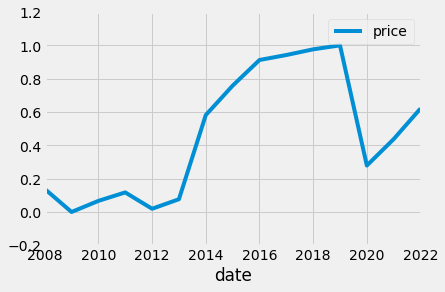

In [ ]:
DAFY.plot(grid=True)
plt.show()

Nearly positive trend.

In [ ]:
DAFY_diff = DAFY.diff(1).dropna()
DAFY_diff.head()

,price
date,
2009-01-01,-0.138512
2010-01-01,0.066530
2011-01-01,0.050895
2012-01-01,-0.098107
2013-01-01,0.057236


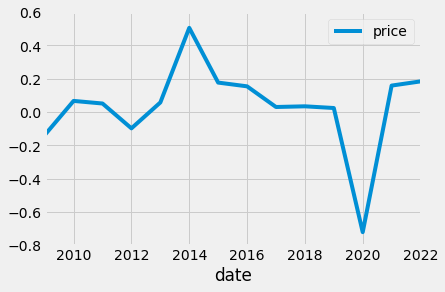

In [ ]:
DAFY_diff.plot(grid=True)
plt.show()

##### Checking Random Walk

In [ ]:
RW_DAFY = adfuller(DAFY_diff)
RW_DAFY[1] # print P-value. If p-value<5%, reject null hypothesis

0.00010520893072316454

##### Plot ACF and PACF

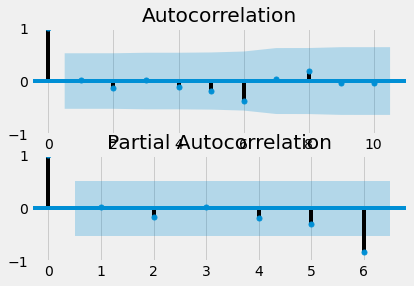

In [ ]:
fig, axes=plt.subplots(2,1)
plot_acf(DAFY_diff, lags=10, ax=axes[0])
plot_pacf(DAFY_diff, lags=6, ax=axes[1])
plt.show()

##### Choose smallest AIC and BIC

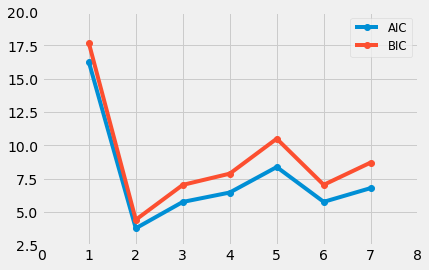

In [ ]:
AIC, BIC = AIC_BIC_withOrderRange(DAFY, p=2, d=2, q=2)
# 0:(0,0,0), 1:(0,0,1), 2:(0,1,0), 3:(0,1,1), 4:(1,0,0), 5:(1,0,1), 6:(1,1,0), 7:(1,1,1)

In [ ]:
AIC, BIC

(array([28.9134554 , 16.2643394 ,  3.77623692,  5.75355812,  6.45790463,
         8.37214789,  5.75915012,  6.79128786]),
 array([29.6215056 , 17.6804398 ,  4.41529425,  7.03167278,  7.87400503,
        10.49629849,  7.03726478,  8.70845985]))

We shouldn't choose the AIC or BIC with values `0.`

##### We will run 2:(0,1,0)

In [ ]:
mod_orders = [
    (0,1,0)
]

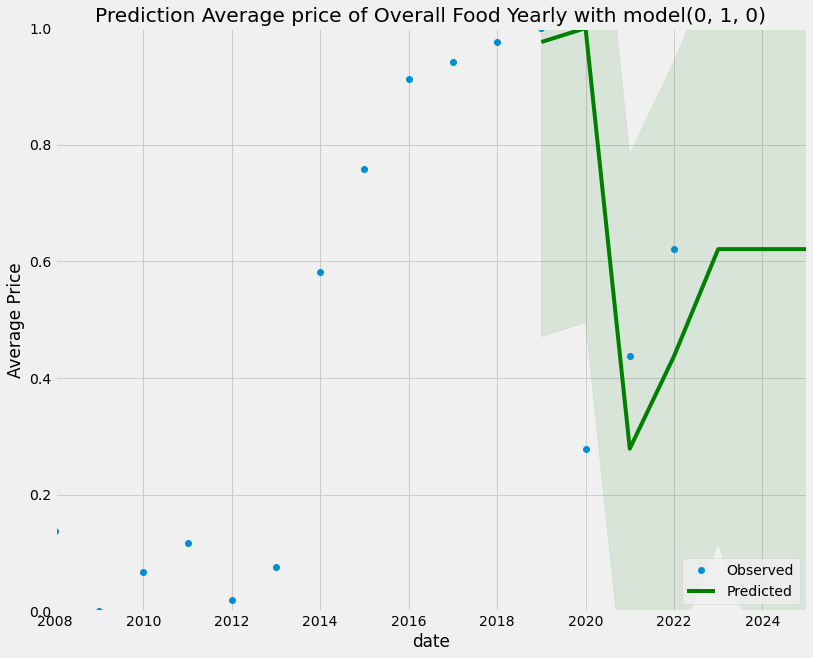

In [ ]:
DAFY_models = []
for ind, order in enumerate(mod_orders): 
    model = Run_SARIMAX(DAFY, mod_order=order, time_range=[[obv_st_date, obv_end_date], [pred_st_date, pred_end_date]], col='price', title='Prediction Average price of Overall Food Yearly with model'+str(order), xlabel='Year', ylabel='Average Price')
    DAFY_models.append(model)

In [ ]:
DAFY_model = DAFY_models[0]

In [ ]:
DAFY_pred_normalized = DAFY_model.predict(pred_st_date, pred_end_date)
DAFY_pred_normalized

2019-01-01    0.976084
2020-01-01    1.000000
2021-01-01    0.278781
2022-01-01    0.437313
2023-01-01    0.620999
2024-01-01    0.620999
2025-01-01    0.620999
Freq: AS-JAN, Name: predicted_mean, dtype: float64

In [ ]:
pred_date = DAFY_pred_normalized.index
pred_date = pred_date[:-1] # the last index doesn't need
pred_date

DatetimeIndex(['2019-01-01', '2020-01-01', '2021-01-01', '2022-01-01',
               '2023-01-01', '2024-01-01'],
              dtype='datetime64[ns]', freq='AS-JAN')

We need to un-normalized the predicted value to get actual price

In [ ]:
# DAFY_pred_normalized['need'] = 0 # Expected 2D array, got 1D array instead
DAFY_pred_normalized_df = pd.DataFrame(DAFY_pred_normalized)
DAFY_pred_normalized_df = DAFY_pred_normalized_df[:-1] # the last index doesn't need
DAFY_pred_normalized_df

,predicted_mean
2019-01-01,0.976084
2020-01-01,1.000000
2021-01-01,0.278781
2022-01-01,0.437313
2023-01-01,0.620999
2024-01-01,0.620999


In [ ]:
DAFY_pred_act = scaler.inverse_transform(DAFY_pred_normalized_df)
DAFY_pred_act_df = pd.DataFrame(DAFY_pred_act)
DAFY_pred_act_df['date'] = pred_date
DAFY_pred_act_df.columns = ['Predicted Price', 'date']
DAFY_pred_act_df.set_index('date')

,Predicted Price
date,
2019-01-01,2196.604882
2020-01-01,2230.693120
2021-01-01,1202.700311
2022-01-01,1428.663670
2023-01-01,1690.482529
2024-01-01,1690.482529
